# 1.1 EDA Summary and Charts

DATA 110 Project 1: Maryland counties, education. This notebook reads the cleaned data from `data/processed/`, summarizes it, and makes the charts. Run `1.0-initial-data-cleaning` first, then run these cells from top to bottom.

## 1. Setup
Import the libraries and set the chart colors and style.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BLUE, GOLD, GRAY, INK = "#1a7fbd", "#e8a81a", "#9aa5b1", "#1f2933"
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": INK, "text.color": INK, "axes.labelcolor": INK})

DATA = "../../data/processed/md_education_clean.csv"
IMG = "../images"              # charts are saved here (eda/images)
FIG = "../../reports/figures"  # and here, for the report and slides
os.makedirs(IMG, exist_ok=True); os.makedirs(FIG, exist_ok=True)

## 2. Load the cleaned data

In [2]:
df = pd.read_csv(DATA)
df.head()

,county,grads,ratio,spend,ba,hs,cc2,cc4,enr2,enr4,short
0,Allegany County,642,13.9,13771,18.3,90.0,1,1,2586.0,4831.0,Allegany
1,Anne Arundel County,5268,14.7,13648,40.9,92.1,1,2,12655.0,548.0,Anne Arundel
2,Baltimore City,4108,16.1,15376,31.2,84.9,1,11,4909.0,59254.0,Baltimore City
3,Baltimore County,7171,15.1,13880,38.6,91.1,1,7,17732.0,42571.0,Baltimore
4,Calvert County,1227,15.7,14062,31.1,93.9,0,0,NaN,NaN,Calvert


## 3. Explore the data
Summary statistics and missing values.

In [3]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
grads,24.0,2444.8,2843.9,146.0,428.5,1201.0,3280.2,10970.0
ratio,24.0,14.2,1.4,11.3,13.2,14.4,15.1,16.3
spend,24.0,14238.8,1281.1,12682.0,13256.0,13850.0,14874.8,17814.0
ba,24.0,32.0,11.5,15.7,22.4,31.4,36.5,61.4
hs,24.0,89.7,3.3,81.9,87.7,90.3,92.1,95.5
cc2,24.0,0.7,0.5,0.0,0.0,1.0,1.0,1.0
cc4,24.0,1.7,2.7,0.0,0.0,1.0,2.0,11.0
enr2,16.0,7093.4,5957.6,648.0,2814.8,5307.0,9952.2,21260.0
enr4,13.0,18452.4,32142.8,548.0,1512.0,3085.0,8617.0,106543.0


In [4]:
print("Missing values:\n", df.isna().sum().to_string())
print("\nBlank enrollments are 'no such college', not unknown:")
print("  enr2 blank & cc2==0:", int((df.enr2.isna() & (df.cc2 == 0)).sum()), "of", int(df.enr2.isna().sum()))
print("  enr4 blank & cc4==0:", int((df.enr4.isna() & (df.cc4 == 0)).sum()), "of", int(df.enr4.isna().sum()), "(Dorchester is the exception)")

Missing values:
 county     0
grads      0
ratio      0
spend      0
ba         0
hs         0
cc2        0
cc4        0
enr2       8
enr4      11
short      0

Blank enrollments are 'no such college', not unknown:
  enr2 blank & cc2==0: 8 of 8
  enr4 blank & cc4==0: 10 of 11 (Dorchester is the exception)


## 4. Correlations
How strongly each pair of measures moves together.

In [5]:
corr = df[["ratio", "spend", "ba", "hs"]].corr()
r_sb, r_rs, r_hb = corr.loc["spend", "ba"], corr.loc["ratio", "spend"], corr.loc["hs", "ba"]
median_ba = df.ba.median()
corr.round(2)

,ratio,spend,ba,hs
ratio,1.00,-0.58,0.20,0.27
spend,-0.58,1.00,0.07,-0.23
ba,0.20,0.07,1.00,0.65
hs,0.27,-0.23,0.65,1.00


## 5. Chart helper
A function that draws a scatter plot with a trend line and labels a few counties.

In [6]:
def save(fig, fname):
    fig.savefig(f"{IMG}/{fname}", dpi=200)
    fig.savefig(f"{FIG}/{fname}", dpi=200)

def scatter(x, y, xl, yl, title, names, fname, r):
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.scatter(df[x], df[y], s=70, color=BLUE, edgecolor="white", zorder=3)
    hi = df[df.short.isin(names)]
    ax.scatter(hi[x], hi[y], s=90, color=GOLD, edgecolor=INK, zorder=4)
    for _, row in hi.iterrows():
        ax.annotate(row.short, (row[x], row[y]), xytext=(7, 6), textcoords="offset points", fontsize=10)
    m, b = np.polyfit(df[x], df[y], 1)
    xs = np.linspace(df[x].min(), df[x].max(), 50)
    ax.plot(xs, m * xs + b, color=GRAY, ls="--", zorder=2)
    ax.set_xlabel(xl); ax.set_ylabel(yl)
    fig.suptitle(title, x=0.01, ha="left", fontsize=15, fontweight="bold")
    ax.set_title(f"Maryland jurisdictions (r = {r:.2f}, n = {len(df)})", loc="left", fontsize=11, color="#52606d")
    fig.tight_layout(); save(fig, fname); plt.show()

## 6. Chart 1: Spending vs. bachelor's degrees

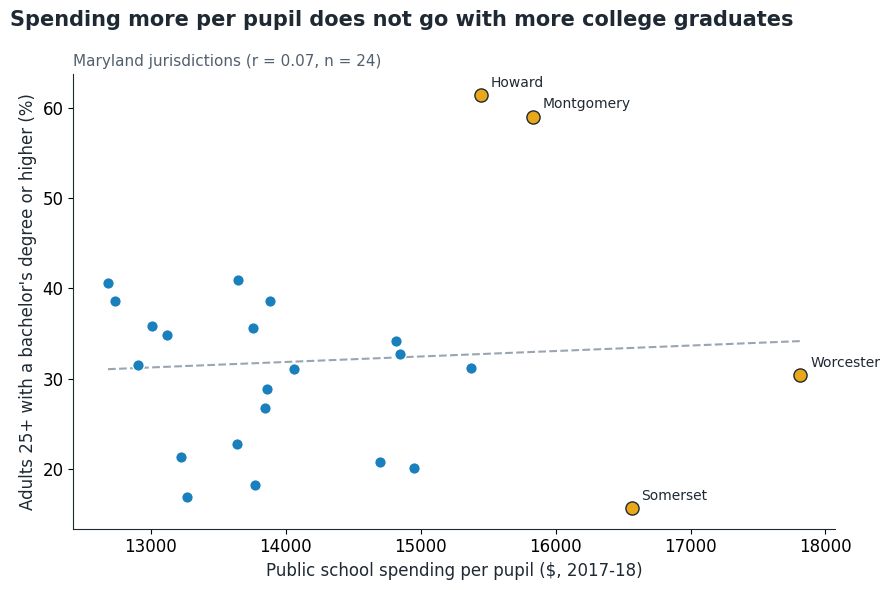

In [7]:
scatter("spend", "ba", "Public school spending per pupil ($, 2017-18)",
        "Adults 25+ with a bachelor's degree or higher (%)",
        "Spending more per pupil does not go with more college graduates",
        ["Howard", "Montgomery", "Somerset", "Worcester"], "fig1_spend_vs_ba.png", r_sb)

## 7. Chart 2: Bachelor's degrees by county

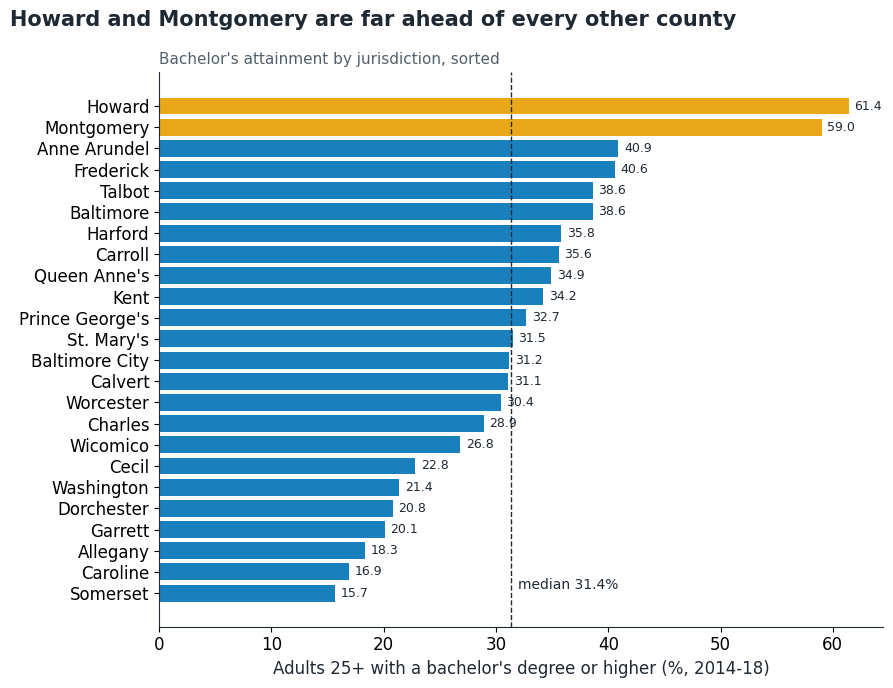

In [8]:
d = df.sort_values("ba")
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(d.short, d.ba, color=[GOLD if s in ("Howard", "Montgomery") else BLUE for s in d.short])
ax.axvline(median_ba, color=INK, ls="--", lw=1)
ax.text(median_ba + 0.6, 0.2, f"median {median_ba:.1f}%", fontsize=10)
for y, v in enumerate(d.ba): ax.text(v + 0.5, y, f"{v:.1f}", va="center", fontsize=9)
ax.set_xlabel("Adults 25+ with a bachelor's degree or higher (%, 2014-18)")
fig.suptitle("Howard and Montgomery are far ahead of every other county", x=0.01, ha="left", fontsize=15, fontweight="bold")
ax.set_title("Bachelor's attainment by jurisdiction, sorted", loc="left", fontsize=11, color="#52606d")
fig.tight_layout(); save(fig, "fig2_ba_by_county.png"); plt.show()

## 8. Chart 3: Class size vs. spending

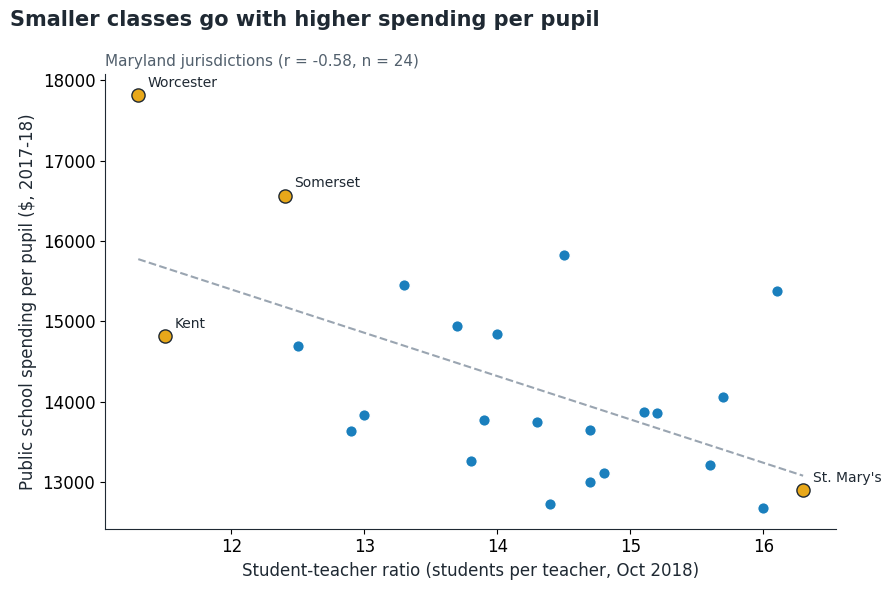

In [9]:
scatter("ratio", "spend", "Student-teacher ratio (students per teacher, Oct 2018)",
        "Public school spending per pupil ($, 2017-18)",
        "Smaller classes go with higher spending per pupil",
        ["Worcester", "Somerset", "Kent", "St. Mary's"], "fig3_ratio_vs_spend.png", r_rs)

## 9. Chart 4 (optional): High school vs. bachelor's degrees

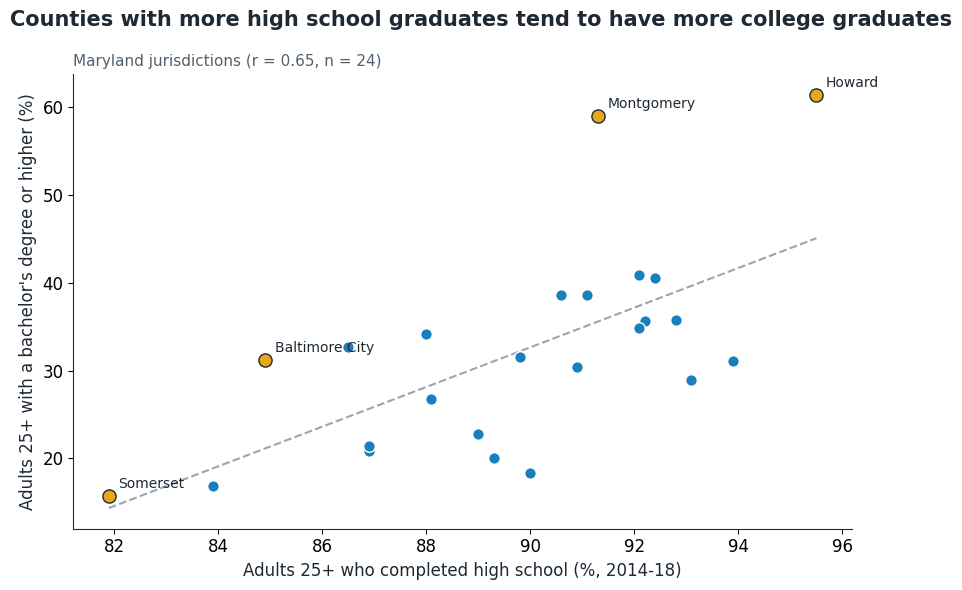

In [10]:
scatter("hs", "ba", "Adults 25+ who completed high school (%, 2014-18)",
        "Adults 25+ with a bachelor's degree or higher (%)",
        "Counties with more high school graduates tend to have more college graduates",
        ["Howard", "Montgomery", "Somerset", "Baltimore City"], "fig4_hs_vs_ba.png", r_hb)